# Wage Case 2: Cost of a Raise
Part of the field tech wage case (see the *Field Tech Wage Case: Analysis Plan* doc).
**Question:** what does a field tech raise cost per year, and how does that compare with what waste already costs?
Sources: the company app's cost settings (`cost_settings`), field hours (`daily_labor`) and waste events. Read-only.

In [1]:
import sys
from datetime import date, timedelta
sys.path.insert(0, "../src")
from supabase_pull import pull, load_waste
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import Markdown, display
pd.set_option("display.float_format", "{:,.2f}".format)

# ---- Parameters ------------------------------------------------------------
RAISES        = [0.50, 1.00, 2.00, 3.00]      # $/hr raise options to price
MOVE_STAGES   = ["move_in", "move_back"]       # daily_labor stages that count as moving / contents work
MOVE_DIFF     = 2.00                           # $/hr differential for moving / contents hours
WC_QB_2025    = 25_800 / 718_726               # workers' comp from 2025 QuickBooks (WC paid / wages)
WASTE_FROM    = "2026-10-12"                   # first tracked week (Monday)
# ---------------------------------------------------------------------------
UP, GREY, INK = "#b42318", "#98a2b3", "#344054"

## Cost settings from the app

In [2]:
cs = pull("select key, label, value, unit, source from cost_settings order by sort_order")
S = dict(zip(cs["key"], pd.to_numeric(cs["value"])))
cs[["label", "value", "unit", "source"]]

,label,value,unit,source
0,Field labor wage,16.00,$/hr,Per Gina
1,Employer payroll taxes,0.08,% of wage,"2025 P&L: $70,595 unlabeled payroll ÷ $893,038..."
2,Workers' comp,0.23,% of wage,"2025 QB WC $25,800 ÷ $718,726 wages · Oct 6 20..."
3,Benefits / other,0.00,% of wage,None identified for field crew
4,Labor billing rate,60.37,$/hr,Xactimate estimates
5,Truck cost per day,94.27,$/day,2025 auto expense + auto insurance ÷ 9 vehicle...
6,Storage carrying cost,0.19,$/sq ft/mo,"Rent, utilities, repairs (75% storage share) +..."
7,Dump cost per dumpster,481.62,$/dumpster,Sinclair QB $963.23 ÷ 2
8,Outsourced laundry — vendor share,0.80,% of laundry billed,Country Day Cleaners (Petrie)
9,2025 revenue,"2,350,521.00",$/yr,2025 P&L


In [3]:
wage, billing   = S["field_wage"], S["billing_rate"]
crew, hours_yr  = S["field_crew"], S["field_hours_year"]
burden = {   # employer cost on top of each $1 of wage
    "App setting": S["payroll_tax_pct"] + S["wc_pct"] + S.get("benefits_pct", 0),
    "2025 QuickBooks": S["payroll_tax_pct"] + WC_QB_2025 + S.get("benefits_pct", 0),
}
pd.DataFrame({
    "workers' comp %": [S["wc_pct"] * 100, WC_QB_2025 * 100],
    "total burden %": [b * 100 for b in burden.values()],
    "loaded cost of $16/hr": [wage * (1 + b) for b in burden.values()],
}, index=list(burden)).round(2)

,workers' comp %,total burden %,loaded cost of $16/hr
App setting,23.35,31.25,21.00
2025 QuickBooks,3.59,11.49,17.84


## Annual cost of a raise for the whole field crew
Cost = crew × hours per year × raise × (1 + burden). Shown under both workers' comp rates until the real rate is confirmed.

In [4]:
rows = []
for r in RAISES:
    row = {"raise ($/hr)": r, "new wage ($/hr)": wage + r}
    for name, b in burden.items():
        row[f"annual cost, {name} ($)"] = crew * hours_yr * r * (1 + b)
    row["loaded cost ($/hr, app)"] = (wage + r) * (1 + burden["App setting"])
    row["loaded as % of billing rate"] = row["loaded cost ($/hr, app)"] / billing * 100
    rows.append(row)
raise_cost = pd.DataFrame(rows).set_index("raise ($/hr)").round(2)
raise_cost

,new wage ($/hr),"annual cost, App setting ($)","annual cost, 2025 QuickBooks ($)","loaded cost ($/hr, app)",loaded as % of billing rate
raise ($/hr),,,,,
0.50,16.50,"21,840.00","18,551.88",21.66,35.87
1.00,17.00,"43,680.00","37,103.77",22.31,36.96
2.00,18.00,"87,360.00","74,207.53",23.62,39.13
3.00,19.00,"131,040.00","111,311.30",24.94,41.31


## A targeted option: differential for moving and contents work

In [5]:
stage_hours = pull("""
    select coalesce(stage, '(none)') as stage, sum(hours_worked) as hours,
           count(distinct job_id) as jobs, min(work_date) as first_day, max(work_date) as last_day
    from daily_labor group by 1 order by 2 desc nulls last""")
stage_hours["hours"] = pd.to_numeric(stage_hours["hours"]).fillna(0)
stage_hours["share_pct"] = stage_hours["hours"] / stage_hours["hours"].sum() * 100
stage_hours.round(1)

,stage,hours,jobs,first_day,last_day,share_pct
0,move_back,539.20,15,2026-10-06,2026-11-09,17.90
1,post_construction_clean,493.70,10,2026-10-07,2026-11-10,16.40
2,move_in,476.00,19,2026-10-02,2026-11-10,15.80
3,office,357.30,0,2026-10-05,2026-11-10,11.90
4,chemical_clean,254.40,9,2026-10-06,2026-11-02,8.40
5,structure_clean,186.60,2,2026-10-05,2026-10-30,6.20
6,residential_clean,144.50,4,2026-10-19,2026-11-05,4.80
7,warehouse,132.00,1,2026-10-05,2026-11-09,4.40
8,non_salvage,126.60,20,2026-10-09,2026-11-10,4.20
9,laundry,96.10,8,2026-10-09,2026-11-10,3.20


In [6]:
move_share = stage_hours.loc[stage_hours["stage"].isin(MOVE_STAGES), "hours"].sum() / stage_hours["hours"].sum()
move_hours_yr = crew * hours_yr * move_share
diff_cost = {name: move_hours_yr * MOVE_DIFF * (1 + b) for name, b in burden.items()}
display(Markdown(
    f"- Moving and contents stages ({', '.join(MOVE_STAGES)}) are **{move_share:.0%}** of logged field hours, "
    f"about {move_hours_yr:,.0f} hours a year for the crew.\n"
    f"- A **${MOVE_DIFF:.2f}/hr** differential on those hours only costs about "
    f"**${diff_cost['App setting']:,.0f}** a year (app setting) or ${diff_cost['2025 QuickBooks']:,.0f} (2025 QuickBooks rate)."))

- Moving and contents stages (move_in, move_back) are **34%** of logged field hours, about 11,219 hours a year for the crew.
- A **$2.00/hr** differential on those hours only costs about **$29,450** a year (app setting) or $25,016 (2025 QuickBooks rate).

## Compared with what waste already costs
Waste is measured weekly in the app. The break-even column is how much waste would have to fall for the raise to pay for itself from waste alone, before counting turnover, rework or collections.

In [7]:
last_sunday = date.today() - timedelta(days=date.today().weekday() + 1)
waste = load_waste(str(pd.Timestamp(WASTE_FROM).date() - timedelta(days=1)), end=str(last_sunday + timedelta(days=2)))
waste = waste[(waste["incident_date"] >= pd.Timestamp(WASTE_FROM).date()) & (waste["incident_date"] <= last_sunday)]
n_weeks = ((last_sunday - pd.Timestamp(WASTE_FROM).date()).days + 1) // 7
weekly = waste["total_cost"].sum() / n_weeks
waste_yr = weekly * 52

options = {f"${r:.2f}/hr raise, all field hours": raise_cost.loc[r, "annual cost, App setting ($)"] for r in RAISES}
options[f"${MOVE_DIFF:.2f}/hr on moving & contents hours"] = diff_cost["App setting"]
compare = pd.DataFrame({"annual cost ($)": options})
compare["break-even waste reduction %"] = compare["annual cost ($)"] / waste_yr * 100
display(Markdown(f"Waste over {n_weeks} weeks ({WASTE_FROM} to {last_sunday}): **${weekly:,.0f} a week**, "
                 f"about **${waste_yr:,.0f} a year** at that pace. Early data: treat as a rough guide."))
compare.round(1)

Waste over 4 weeks (2026-10-12 to 2026-11-08): **$1,117 a week**, about **$58,092 a year** at that pace. Early data: treat as a rough guide.

,annual cost ($),break-even waste reduction %
"$0.50/hr raise, all field hours","21,840.00",37.60
"$1.00/hr raise, all field hours","43,680.00",75.20
"$2.00/hr raise, all field hours","87,360.00",150.40
"$3.00/hr raise, all field hours","131,040.00",225.60
$2.00/hr on moving & contents hours,"29,449.70",50.70


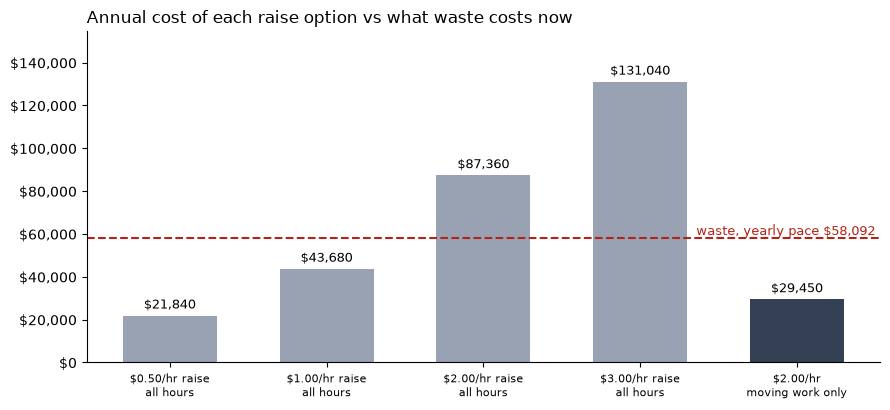

In [8]:
# Memo chart: annual cost of each option vs the yearly pace of waste
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = [l.replace(", all field hours", "\nall hours").replace(" on moving & contents hours", "\nmoving work only")
          for l in compare.index]
bars = ax.bar(labels, compare["annual cost ($)"], color=[GREY] * len(RAISES) + [INK], width=0.6)
ax.bar_label(bars, labels=[f"${v:,.0f}" for v in compare["annual cost ($)"]], padding=3, fontsize=9)
ax.axhline(waste_yr, color=UP, ls="--", lw=1.5)
ax.text(len(labels) - 0.5, waste_yr, f"  waste, yearly pace ${waste_yr:,.0f}", color=UP, va="bottom", ha="right", fontsize=9)
ax.set_title("Annual cost of each raise option vs what waste costs now", loc="left")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.set_ylim(0, max(compare["annual cost ($)"].max(), waste_yr) * 1.18)
ax.tick_params(axis="x", labelsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## In context of the company's finances

In [9]:
profit_2025 = S["rev_2025"] - S["cogs_2025"] - S["opex_2025"]
context = pd.Series({
    "2025 revenue ($)": S["rev_2025"],
    "2025 left after all costs ($)": profit_2025,
    "2025 margin %": profit_2025 / S["rev_2025"] * 100,
    "2026 revenue run-rate ($)": S["revenue_run_rate"],
    "Run-rate change vs 2025 %": (S["revenue_run_rate"] / S["rev_2025"] - 1) * 100,
    "$1/hr raise as % of 2025 profit": raise_cost.loc[1.00, "annual cost, App setting ($)"] / profit_2025 * 100,
    "Move differential as % of 2025 profit": diff_cost["App setting"] / profit_2025 * 100,
})
context.round(1).to_frame("value")

,value
2025 revenue ($),"2,350,521.00"
2025 left after all costs ($),"212,752.00"
2025 margin %,9.10
2026 revenue run-rate ($),"1,927,098.00"
Run-rate change vs 2025 %,-18.00
$1/hr raise as % of 2025 profit,20.50
Move differential as % of 2025 profit,13.80


## Notes
- Workers' comp: the app setting (23.35%) was set so loaded cost equals $21.00/hr; 2025 QuickBooks works out to about 3.6%. Confirm the real rate; it moves every cost here.
- Hours per person (2,080) assume full-time, year-round. Actual paid hours from payroll would be more exact.
- Waste pace covers only a few weeks and only logged events. It understates the full cost of turnover and rework.
- Moving share uses logged hours since the labor log started; update `MOVE_STAGES` if other stages count as contents work.